# Задание 4. Предсказание года выпуска песни

Нейронная сеть решает задачу регрессии по 90 числовым признакам; итоговые предсказания округляются до целого года. Качество оценивается по MSE. Сравниваются встроенный `AdamW` и самостоятельно реализованный `CustomAdamW`.

Для этого соревнования использованы только `train_x.csv`, `train_y.csv` и `test_x.csv`. Обучающие таблицы связываются по `Unnamed: 0`, а при отправке предсказаний используются идентификаторы `id` из тестового файла. Дополнительные внешние данные не используются.

In [1]:
import copy
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
BATCH_SIZE = 256
MAX_EPOCHS = 50
PATIENCE = 10
MAX_TRAIN_ROWS = None
VALIDATION_FRACTION = 0.2
LEARNING_RATE = 7e-4
WEIGHT_DECAY = 0.01
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})
print("Устройство:", DEVICE)

Устройство: cpu


## 1. Исходные данные и сопоставление наблюдений

Файлы соревнования содержат 90 числовых признаков `0`–`89`. В `train_x.csv` и `train_y.csv` один и тот же идентификатор находится в столбце `Unnamed: 0`; целевая переменная называется `year`. В `test_x.csv` идентификатор находится в отдельном столбце `id`.

Обучающие признаки и целевые годы соединяются **по идентификатору**, а не по предположению о порядке строк. Идентификаторы исключаются из входа нейронной сети. Для Kaggle сохраняется исходный порядок `test_x.csv` и значения его столбца `id`.

In [2]:
WINDOWS_DATA_DIR = Path(r"C:\Users\annap\VSCode\python\spbu_dl_2026\homeworks\04_kaggle\data")
CANDIDATES = [
    Path.cwd() / "data",
    Path.cwd() / "04_kaggle" / "data",
    Path.cwd() / "homeworks" / "04_kaggle" / "data",
    Path.cwd().parent / "04_kaggle" / "data",
    Path.cwd().parent / "homeworks" / "04_kaggle" / "data",
    WINDOWS_DATA_DIR,
]
DATA_DIR = next(
    (path for path in CANDIDATES if all((path / name).is_file()
     for name in ("train_x.csv", "train_y.csv", "test_x.csv"))),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("Не найдены train_x.csv, train_y.csv и test_x.csv в одной папке data")

train_x_frame = pd.read_csv(DATA_DIR / "train_x.csv", encoding="utf-8-sig")
train_y_frame = pd.read_csv(DATA_DIR / "train_y.csv", encoding="utf-8-sig")
test_x_frame = pd.read_csv(DATA_DIR / "test_x.csv", encoding="utf-8-sig")

assert "Unnamed: 0" in train_x_frame.columns, "Нет идентификаторов в train_x.csv"
assert set(train_y_frame.columns) == {"Unnamed: 0", "year"}, "Неожиданные столбцы train_y.csv"
assert "id" in test_x_frame.columns, "Нет идентификаторов в test_x.csv"

train_x_frame = train_x_frame.rename(columns={"Unnamed: 0": "train_id"})
train_y_frame = train_y_frame.rename(columns={"Unnamed: 0": "train_id"})
assert train_x_frame["train_id"].is_unique and train_y_frame["train_id"].is_unique
assert train_x_frame["train_id"].notna().all() and train_y_frame["train_id"].notna().all()
assert test_x_frame["id"].is_unique and test_x_frame["id"].notna().all()

train_y_frame = train_x_frame[["train_id"]].merge(
    train_y_frame,
    on="train_id",
    how="left",
    validate="one_to_one",
    sort=False,
)
assert train_y_frame["year"].notna().all(), "Не все обучающие записи имеют год выпуска"
assert len(train_x_frame) == len(train_y_frame) == 14000
assert len(test_x_frame) == 6000

print("Папка:", DATA_DIR)
print("Размеры:", train_x_frame.shape, train_y_frame.shape, test_x_frame.shape)
print("Примеры ID обучения:", train_x_frame["train_id"].head().tolist())
print("Примеры ID теста:", test_x_frame["id"].head().tolist())
print("Связь признаков и годов: по train_id")

Папка: c:\Users\annap\VSCode\python\spbu_dl_2026\homeworks\04_kaggle\data
Размеры: (14000, 91) (14000, 2) (6000, 91)
Примеры ID обучения: [133081, 111484, 448402, 254414, 272580]
Примеры ID теста: [3416, 18991, 11105, 18902, 18958]
Связь признаков и годов: по train_id


In [3]:
feature_columns = [str(i) for i in range(90)]
assert [c for c in train_x_frame.columns if c != "train_id"] == feature_columns
assert [c for c in test_x_frame.columns if c != "id"] == feature_columns

train_features_df = train_x_frame[feature_columns].apply(pd.to_numeric, errors="raise")
test_features_df = test_x_frame[feature_columns].apply(pd.to_numeric, errors="raise")
raw_target = pd.to_numeric(train_y_frame["year"], errors="raise")
assert np.isfinite(train_features_df.to_numpy()).all()
assert np.isfinite(test_features_df.to_numpy()).all()
assert np.isfinite(raw_target.to_numpy()).all()

train_frame = train_features_df.copy()
test_frame = test_features_df.copy()
TARGET = "__target_year__"
train_frame[TARGET] = raw_target.to_numpy()
features = feature_columns
TEST_IDS = test_x_frame["id"].to_numpy(dtype=np.int64, copy=True)

print(f"Обучающих записей: {len(train_frame):,}; тестовых: {len(test_frame):,}; признаков: {len(features)}")
print(f"Целевая переменная: year; диапазон: {raw_target.min():.0f}–{raw_target.max():.0f}")
print("Пропусков в данных:", int(train_frame.isna().sum().sum() + test_frame.isna().sum().sum()))
display(train_x_frame[["train_id", "0", "1", "89"]].head(3))
display(train_y_frame.head(3))

Обучающих записей: 14,000; тестовых: 6,000; признаков: 90
Целевая переменная: year; диапазон: 1922–2011
Пропусков в данных: 0


,train_id,0,1,89
0,133081,37.47518,-14.34414,-61.48682
1,111484,48.17393,-7.02208,-1.91676
2,448402,36.58141,26.03203,-8.47276


,train_id,year
0,133081,2001
1,111484,2006
2,448402,1989


## 2. Валидация и предобработка

Случайным образом выделяется 20% размеченных записей для валидации. Пропущенные значения заполняются медианами, а признаки стандартизируются по статистикам обучающей части. Для оценки используется **MSE в годах²**, совпадающая с метрикой соревнования; дополнительно выводится RMSE в годах. Сравнивается ошибка нейросети и простой прогноз среднего года.

In [4]:
all_features = train_frame[features].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float32)
all_target = pd.to_numeric(train_frame[TARGET], errors="coerce").to_numpy(dtype=np.float32)
test_features = test_frame[features].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float32)

valid_targets = np.isfinite(all_target)
all_features = all_features[valid_targets]
all_target = all_target[valid_targets]

rng = np.random.default_rng(SEED)
selection = rng.permutation(len(all_target))
if MAX_TRAIN_ROWS is not None:
    selection = selection[:min(MAX_TRAIN_ROWS, len(selection))]
all_features = all_features[selection]
all_target = all_target[selection]

cutoff = max(1, min(len(all_target) - 1, int(len(all_target) * (1 - VALIDATION_FRACTION))))
assert len(all_target) >= 3, "Недостаточно обучающих строк"
train_indices = np.arange(cutoff)
valid_indices = np.arange(cutoff, len(all_target))

class FeatureScaler:
    def fit(self, values):
        values = np.where(np.isfinite(values), values, np.nan)
        self.median = np.nanmedian(values, axis=0)
        self.median = np.nan_to_num(self.median, nan=0.0)
        filled = np.where(np.isfinite(values), values, self.median)
        self.mean = filled.mean(axis=0)
        self.std = filled.std(axis=0)
        self.std = np.where(self.std < 1e-6, 1.0, self.std)
        return self

    def transform(self, values):
        values = np.where(np.isfinite(values), values, self.median)
        return np.clip((values - self.mean) / self.std, -10, 10).astype(np.float32)

scaler = FeatureScaler().fit(all_features[train_indices])
x_train = scaler.transform(all_features[train_indices])
x_valid = scaler.transform(all_features[valid_indices])
y_train_real = all_target[train_indices]
y_valid_real = all_target[valid_indices]
y_mean = float(y_train_real.mean())
y_std = max(float(y_train_real.std()), 1.0)
y_train = ((y_train_real - y_mean) / y_std).astype(np.float32)
y_valid = ((y_valid_real - y_mean) / y_std).astype(np.float32)

train_dataset = TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train))
valid_dataset = TensorDataset(torch.from_numpy(x_valid), torch.from_numpy(y_valid))
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)
print(f"Train: {len(train_dataset):,}, validation: {len(valid_dataset):,}, признаки: {x_train.shape[1]}")
print(f"Год: среднее {y_mean:.2f}, стандартное отклонение {y_std:.2f}")
validation_baseline_mse = float(np.mean((y_valid_real - y_train_real.mean()) ** 2))
print(f"MSE прогноза среднего года на валидации: {validation_baseline_mse:.3f}")

Train: 11,200, validation: 2,800, признаки: 90
Год: среднее 1998.38, стандартное отклонение 11.07
MSE прогноза среднего года на валидации: 120.492


In [5]:
assert len(feature_columns) == 90
assert "train_id" not in features and "id" not in features
assert len(train_x_frame) == len(train_y_frame) == 14000
assert len(test_x_frame) == 6000
assert np.array_equal(TEST_IDS, test_x_frame["id"].to_numpy())
assert np.array_equal(train_x_frame["train_id"].to_numpy(), train_y_frame["train_id"].to_numpy())
assert list(train_frame.columns[:-1]) == feature_columns
print("Проверки пройдены: 90 признаков, X/Y соединены по ID, id не является признаком")

Проверки пройдены: 90 признаков, X/Y соединены по ID, id не является признаком


## 3. Архитектура и оптимизаторы

Используется полносвязная нейросеть с двумя скрытыми блоками по 256 и 128 нейронов, нормализацией `LayerNorm`, нелинейностью `GELU` и регуляризацией `Dropout(0.1)`. Финальный слой возвращает одно действительное число.

Ниже приведена самостоятельная реализация AdamW (такой же алгоритм, как в третьем задании). Для неё не используется `torch.optim.AdamW`.

In [6]:
class YearRegressor(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_features, 256), nn.LayerNorm(256), nn.GELU(), nn.Dropout(0.1),
            nn.Linear(256, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(0.1),
            nn.Linear(128, 64), nn.GELU(),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.layers(x).squeeze(-1)

class CustomAdamW:
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.01):
        self.params = [p for p in params if p.requires_grad]
        self.lr, self.betas, self.eps, self.weight_decay = lr, betas, eps, weight_decay
        self.state = {}

    @torch.no_grad()
    def step(self):
        beta1, beta2 = self.betas
        for param in self.params:
            if param.grad is None:
                continue
            grad = param.grad
            if param not in self.state:
                self.state[param] = [0, torch.zeros_like(param), torch.zeros_like(param)]
            state = self.state[param]
            state[0] += 1
            step, mean, variance = state
            mean.mul_(beta1).add_(grad, alpha=1 - beta1)
            variance.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)
            param.mul_(1 - self.lr * self.weight_decay)
            corrected_mean = mean / (1 - beta1 ** step)
            corrected_variance = variance / (1 - beta2 ** step)
            param.addcdiv_(corrected_mean, corrected_variance.sqrt().add(self.eps), value=-self.lr)

    def zero_grad(self, set_to_none=True):
        for param in self.params:
            if set_to_none:
                param.grad = None
            elif param.grad is not None:
                param.grad.zero_()

OPTIMIZER_FACTORIES = {
    "AdamW (torch)": lambda params: torch.optim.AdamW(params, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY),
    "AdamW (custom)": lambda params: CustomAdamW(params, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY),
}

assert YearRegressor(len(features))(torch.zeros(4, len(features))).shape == (4,)

## 4. Обучение и сравнение

Для каждого оптимизатора стартовая инициализация и порядок обучающих объектов одинаковы. На каждой эпохе считается средняя ошибка MSE при обучении, затем MAE и RMSE в годах на валидации. Лучшие параметры сохраняются в памяти. Если валидационная RMSE не улучшается в течение заданного числа эпох, обучение останавливается.

In [7]:
def metric_on_validation(model, loader, target_mean, target_std):
    model.eval()
    predictions = []
    targets = []
    with torch.inference_mode():
        for x, y in loader:
            normalized_prediction = model(x.to(DEVICE)).cpu().numpy()
            predictions.append(normalized_prediction * target_std + target_mean)
            targets.append(y.numpy() * target_std + target_mean)
    pred = np.concatenate(predictions)
    target = np.concatenate(targets)
    mae = float(np.mean(np.abs(pred - target)))
    rmse = float(np.sqrt(np.mean((pred - target) ** 2)))
    return mae, rmse, pred, target

def experiment(optimizer_name, optimizer_factory):
    torch.manual_seed(SEED)
    model = YearRegressor(len(features)).to(DEVICE)
    optimizer = optimizer_factory(model.parameters())
    loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED), num_workers=0)
    best_rmse = float("inf")
    best_epoch = 0
    best_weights = None
    no_improvement = 0
    rows = []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        total_mse, total_count = 0.0, 0
        for x, target in loader:
            x, target = x.to(DEVICE), target.to(DEVICE)
            optimizer.zero_grad()
            loss = F.mse_loss(model(x), target)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            total_mse += loss.item() * len(target)
            total_count += len(target)
        val_mae, val_rmse, _, _ = metric_on_validation(model, valid_loader, y_mean, y_std)
        rows.append({"optimizer": optimizer_name, "epoch": epoch,
                     "train_mse_normalized": total_mse / total_count,
                     "val_mae_years": val_mae, "val_rmse_years": val_rmse, "val_mse_years2": val_rmse ** 2})
        if val_rmse < best_rmse - 1e-4:
            best_rmse = val_rmse
            best_epoch = epoch
            best_weights = copy.deepcopy(model.state_dict())
            no_improvement = 0
        else:
            no_improvement += 1
        if epoch == 1 or epoch % 5 == 0 or no_improvement >= PATIENCE:
            print(f"{optimizer_name}: эпоха {epoch}, RMSE={val_rmse:.3f}, MAE={val_mae:.3f}")
        if no_improvement >= PATIENCE:
            break
    model.load_state_dict(best_weights)
    return {"history": rows, "model": model, "best_epoch": best_epoch,
            "best_rmse": best_rmse, "best_weights": best_weights}

experiments = {}
for name, factory in OPTIMIZER_FACTORIES.items():
    experiments[name] = experiment(name, factory)

history = pd.DataFrame([row for item in experiments.values() for row in item["history"]])
summary = pd.DataFrame([
    {"optimizer": name, "best_epoch": item["best_epoch"], "val_rmse_years": item["best_rmse"], "val_mse_years2": item["best_rmse"] ** 2}
    for name, item in experiments.items()
]).sort_values("val_mse_years2")
display(summary.round(4))
print(f"Baseline MSE: {validation_baseline_mse:.3f}")
print(f"Best model MSE: {summary.iloc[0]['val_mse_years2']:.3f}")
if summary.iloc[0]["val_mse_years2"] >= validation_baseline_mse:
    print("Внимание: нейросеть пока не улучшила прогноз среднего года на валидации")

AdamW (torch): эпоха 1, RMSE=9.506, MAE=6.836
AdamW (torch): эпоха 5, RMSE=9.465, MAE=6.465
AdamW (torch): эпоха 10, RMSE=9.652, MAE=6.408
AdamW (torch): эпоха 13, RMSE=9.790, MAE=6.467
AdamW (custom): эпоха 1, RMSE=9.506, MAE=6.836
AdamW (custom): эпоха 5, RMSE=9.465, MAE=6.465
AdamW (custom): эпоха 10, RMSE=9.652, MAE=6.408
AdamW (custom): эпоха 13, RMSE=9.790, MAE=6.467


,optimizer,best_epoch,val_rmse_years,val_mse_years2
0,AdamW (torch),3,9.3582,87.5765
1,AdamW (custom),3,9.3582,87.5765


Baseline MSE: 120.492
Best model MSE: 87.577


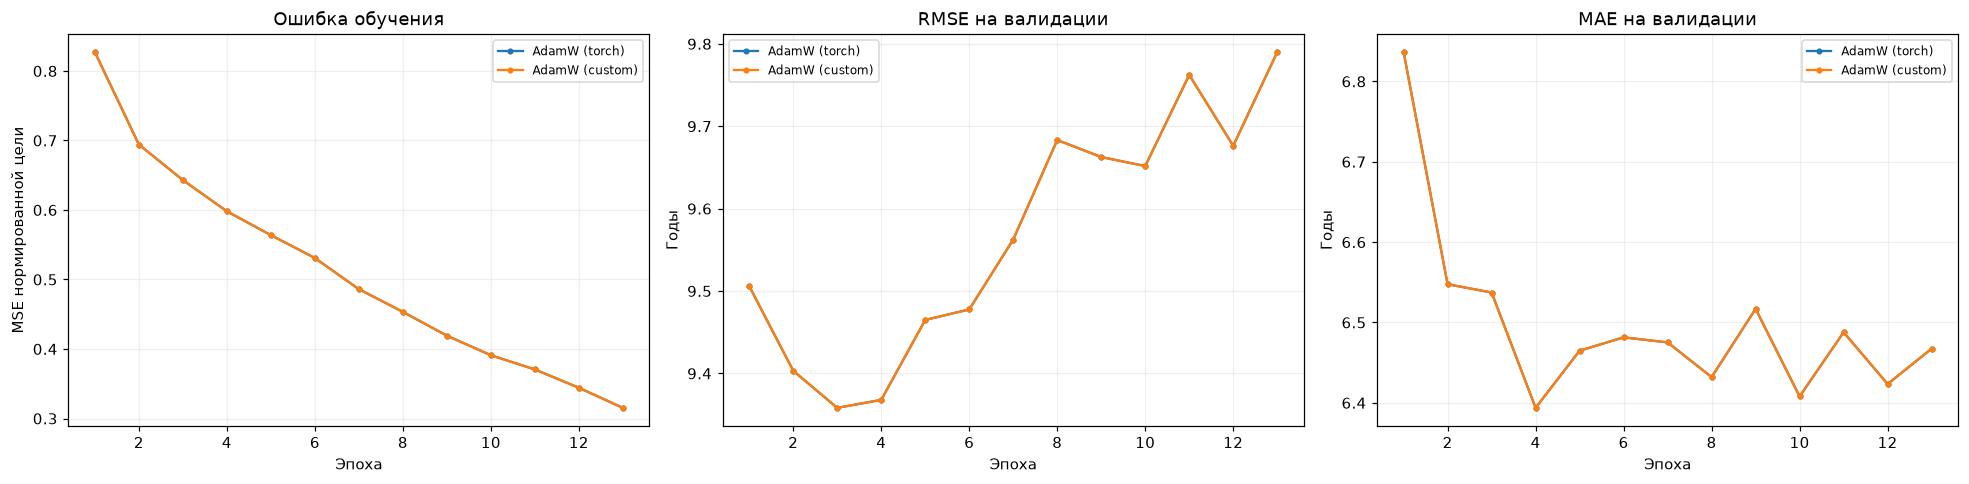

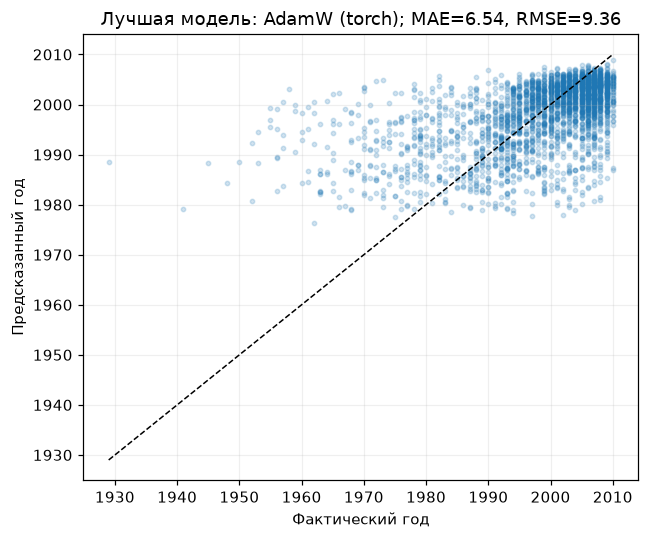

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for name in OPTIMIZER_FACTORIES:
    part = history[history.optimizer == name]
    axes[0].plot(part.epoch, part.train_mse_normalized, marker=".", label=name)
    axes[1].plot(part.epoch, part.val_rmse_years, marker=".", label=name)
    axes[2].plot(part.epoch, part.val_mae_years, marker=".", label=name)
for axis, title, ylabel in zip(axes,
    ["Ошибка обучения", "RMSE на валидации", "MAE на валидации"],
    ["MSE нормированной цели", "Годы", "Годы"]):
    axis.set_title(title)
    axis.set_xlabel("Эпоха")
    axis.set_ylabel(ylabel)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

best_name = summary.iloc[0]["optimizer"]
best_model = experiments[best_name]["model"]
mae, rmse, predicted, actual = metric_on_validation(best_model, valid_loader, y_mean, y_std)
fig, axis = plt.subplots(figsize=(6, 5))
axis.scatter(actual, predicted, s=8, alpha=0.2)
bounds = [min(actual.min(), predicted.min()), max(actual.max(), predicted.max())]
axis.plot(bounds, bounds, linestyle="--", color="black", linewidth=1)
axis.set_xlabel("Фактический год")
axis.set_ylabel("Предсказанный год")
axis.set_title(f"Лучшая модель: {best_name}; MAE={mae:.2f}, RMSE={rmse:.2f}")
plt.tight_layout()
plt.show()

## 5. Итоговое обучение

Сеть обучается заново на всех размеченных строках; оптимизатор и количество эпох выбираются по отложенной валидации. Затем выполняется прогноз для тестовой выборки в том же порядке, что и в `test_x.csv`.

In [9]:
final_scaler = FeatureScaler().fit(all_features)
x_full = final_scaler.transform(all_features)
x_test = final_scaler.transform(test_features)
final_target_mean = float(all_target.mean())
final_target_std = max(float(all_target.std()), 1.0)
y_full = ((all_target - final_target_mean) / final_target_std).astype(np.float32)

full_dataset = TensorDataset(torch.from_numpy(x_full), torch.from_numpy(y_full))
full_loader = DataLoader(full_dataset, batch_size=BATCH_SIZE, shuffle=True,
                         generator=torch.Generator().manual_seed(SEED), num_workers=0)

torch.manual_seed(SEED)
final_model = YearRegressor(len(features)).to(DEVICE)
final_optimizer = OPTIMIZER_FACTORIES[best_name](final_model.parameters())
final_epochs = int(experiments[best_name]["best_epoch"])
for epoch in range(1, final_epochs + 1):
    final_model.train()
    for x, target in full_loader:
        x, target = x.to(DEVICE), target.to(DEVICE)
        final_optimizer.zero_grad()
        loss = F.mse_loss(final_model(x), target)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(final_model.parameters(), max_norm=5.0)
        final_optimizer.step()

final_model.eval()
test_loader = DataLoader(torch.from_numpy(x_test), batch_size=BATCH_SIZE)
test_predictions = []
with torch.inference_mode():
    for x in test_loader:
        prediction = final_model(x.to(DEVICE)).cpu().numpy()
        test_predictions.append(prediction * final_target_std + final_target_mean)
test_predictions = np.concatenate(test_predictions)
assert len(test_predictions) == len(test_frame)
assert np.isfinite(test_predictions).all()
print(f"Итог: {best_name}, эпох: {final_epochs}, тестовых прогнозов: {len(test_predictions)}")

Итог: AdamW (torch), эпох: 3, тестовых прогнозов: 6000


## 6. Submission для Kaggle

Сохраняются именно те `id`, которые присутствуют в исходном файле `test_x.csv`; они не генерируются из номеров строк. По требованиям соревнования прогнозы округляются до целого года. Формат файла: `id,label`, без дополнительных строк и индекса DataFrame.

In [10]:
predictions = np.asarray(test_predictions, dtype=np.float64).reshape(-1)
assert len(predictions) == len(TEST_IDS) == len(test_x_frame) == len(test_frame) == 6000
assert np.isfinite(predictions).all()

predicted_years = np.rint(predictions).astype(np.int64)
submission = pd.DataFrame({"id": TEST_IDS, "label": predicted_years})
assert submission.columns.tolist() == ["id", "label"]
assert submission["id"].equals(test_x_frame["id"].reset_index(drop=True))
assert submission["id"].is_unique
assert submission.notna().all().all()

SUBMISSION_PATH = DATA_DIR.parent / "submission.csv"
submission.to_csv(SUBMISSION_PATH, index=False)
check = pd.read_csv(SUBMISSION_PATH)
assert check.shape == (6000, 2)
assert check.columns.tolist() == ["id", "label"]
assert check["id"].equals(test_x_frame["id"].reset_index(drop=True))
assert (check["label"] == check["label"].astype(np.int64)).all()
print("Файл сохранён:", SUBMISSION_PATH)
print("Формат:", check.shape, check.columns.tolist())
print("Пропуски:", check.isna().sum().to_dict())
display(check.head(5))
display(check.tail(5))

Файл сохранён: c:\Users\annap\VSCode\python\spbu_dl_2026\homeworks\04_kaggle\submission.csv
Формат: (6000, 2) ['id', 'label']
Пропуски: {'id': 0, 'label': 0}


,id,label
0,3416,2000
1,18991,2004
2,11105,1998
3,18902,2002
4,18958,2002


,id,label
5995,15293,2002
5996,7469,1990
5997,6586,1987
5998,17875,1990
5999,17290,1991


## Выводы

Проверены два оптимизатора: встроенный `torch.optim.AdamW` и собственный `CustomAdamW`. Основная метрика — MSE в квадратных годах; дополнительно вычисляются RMSE и MAE. Для итоговой модели используется оптимизатор с наименьшей валидационной ошибкой.

Обучающие ID (`Unnamed: 0`) служат для точного сопоставления признаков и годов, а тестовые ID (`id`) используются при формировании файла для Kaggle. Сами ID не передаются нейронной сети. Итоговый `submission.csv` содержит ровно 6000 строк и два столбца: `id,label`, где `label` — целочисленный год.

**Источники:** [условие соревнования](https://www.kaggle.com/t/dace4caa40384c86a9879217eaccab42), [документация PyTorch: AdamW](https://pytorch.org/docs/stable/generated/torch.optim.AdamW.html).